# Search: Solving a Maze Using a Goal-based Agent — Lab 02, Bài 8

**Student Name:** [Điền họ và tên]  ·  **Student ID:** [Điền MSSV]

**AI tools used:** ChatGPT (hỗ trợ giải thích, viết và kiểm thử mã Python; cần đọc hiểu và xác nhận kết quả trước khi nộp).

**Academic integrity:** [Điền chữ ký viết tắt] — Tôi chịu trách nhiệm về nội dung và kết quả bài làm.

**Ghi chú:** Các cell bài tập gốc được giữ theo thứ tự. Các cell có nhãn "Lời giải" do người học bổ sung.

## Learning Outcomes

* Formulate search problems using key components like initial state, actions, and goal state in a deterministic, fully observable environment.
* Implement and compare search algorithms including BFS, DFS, GBFS, A*, and IDS for planning paths through mazes.
* Analyze algorithm performance by measuring path cost, node expansions, depth, and memory usage across various maze types.
* Use visualization tools to represent maze paths and support debugging and analysis.

## Instructions

Total Points: Undergrads 100 + 5 bonus / Graduate students 110

Complete this notebook. Use the provided notebook cells and insert additional code and markdown cells as needed. Submit the notebook file and the completely rendered notebook with all outputs as a HTML file. 


## Introduction

In this exercise, we will implement the planning function for a type of goal-based agent called a __planning agent__. The planning function uses a map it is given to plan a path through the maze from the starting location $S$ to the goal location $G$. We will only focus on the planning function, so you do not need to implement an environment, just use the map to search for a path to solve the maze. 

Once the plan is made, the agent in a deterministic environment (i.e., the transition function is deterministic with the outcome of each state/action pair fixed and no randomness) can just follow the plan step-by-step and does not need to care about the percepts.
This is also called an **[open-loop system](https://en.wikipedia.org/wiki/Open-loop_controller).**
The execution phase is trivial and can be executed using a model-based reflex agent 
that ignores all percepts and just follows the plan. I will show you a short example, but you do not implement it in this exercise.

Given that the agent has a complete and correct map, the environment is **fully observable, discrete, deterministic, and known.** 
Remember:

* **Fully observable** means that the agent can see its state and what the available actions are. That means the **percepts contain the complete current state.**
Here, during planning, the agent always sees its x and y coordinates on the map and
also seeks when it has reached the goal state. 
* **Discrete** means that we have a **finite set of states.** The maze has a finite set 
of squares the agent can be in.
* **Deterministic** means that the **transition function contains no randomness.** An action in a state will always produce the same result. Going south from the start state always will lead to the same square.
* **Know** means that the agent **knows the complete transition function.** The 
agent has the map and therefore knows how its position changes when it walks in a direction.

Tree search algorithm implementations that you find online typically come from data structures courses and have a different aim than AI tree search. These algorithms assume that you already have a tree in memory. We are interested in dynamically creating a search tree with the aim of finding a good/the best path from the root note to the goal state. Follow the pseudo code presented in the text book (and replicated in the slides) closely. Ideally, we would like to search only a small part of the maze, i.e., create a search tree with as few nodes as possible. 

Several mazes for this exercise are stored as text files. We need to make sure that they are locally available.

In [1]:
# change directory to Google Drive for Google Colab
try:
    from google.colab import drive
    import os

    drive.mount('/content/drive')
    os.chdir('/content/drive/My Drive/Colab Notebooks/')
    print("Your working directory is now Google Drive: My Drive > Colab Notebooks")
except ImportError:
    pass

In [2]:
import urllib.request
import os

def download(file, base_url):
    if not os.path.exists(file):
        urllib.request.urlretrieve(base_url + file, file)

base_url = "https://raw.githubusercontent.com/mhahsler/Introduction_to_Artificial_Intelligence/refs/heads/master/Search/"
download("maze_helper.py", base_url)

mazes = ["small_maze.txt", "medium_maze.txt", "large_maze.txt", "L_maze.txt", "empty_maze.txt", "empty_maze_2.txt", "loops_maze.txt", "open_maze.txt", ]
for maze in mazes:
    download(maze, base_url)

Here is the small example maze:

In [3]:
with open("small_maze.txt", "r") as f:
    maze_str = f.read()
print(maze_str)

XXXXXXXXXXXXXXXXXXXXXX
X XX        X X      X
X    XXXXXX X XXXXXX X
XXXXXX     S  X      X
X    X XXXXXX XX XXXXX
X XXXX X         X   X
X        XXX XXX   X X
XXXXXXXXXX    XXXXXX X
XG         XX        X
XXXXXXXXXXXXXXXXXXXXXX



**Note:** If you get an error here that the file cannot be found, then you need to download it. See [HOWTO Work on Assignments.](https://github.com/mhahsler/CS7320-AI/blob/master/HOWTOs/working_on_assignments.md)

## Parsing and pretty printing the maze

The maze can also be displayed in color using code in the module [maze_helper.py](maze_helper.py). The code parses the string representing the maze and converts it into a `numpy` 2d array which you can use in your implementation. Position are represented as a 2-tuple of the form `(row, col)`. 

In [4]:
import maze_helper as mh

maze = mh.parse_maze(maze_str)

# look at a position in the maze by subsetting the 2d array
print("Position(0,0):", maze[0, 0])

# there is also a helper function called `look(maze, pos)` available
# which uses a 2-tuple for the position.
print("Position(8,1):", mh.look(maze, (8, 1)))

Position(0,0): X
Position(8,1): G


A helper function to visualize the maze is also available.

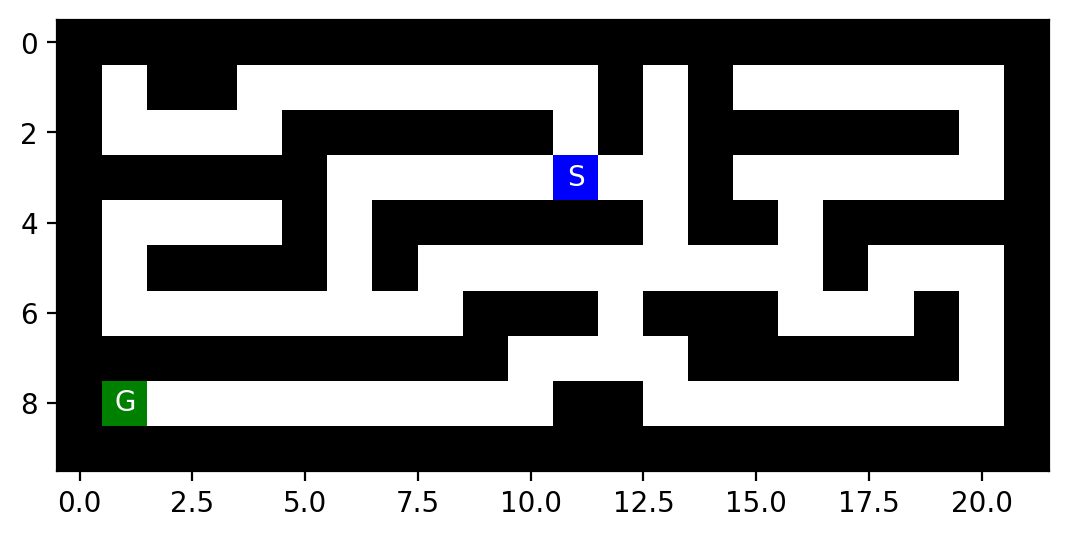

In [5]:
%matplotlib inline
%config InlineBackend.figure_format = 'retina'
# use higher resolution images in notebooks

mh.show_maze(maze)

Find the `(x,y)` position of the start and the goal using the helper function `find_pos()`

In [6]:
print("Start location:", mh.find_pos(maze, what = "S"))
print("Goal location:", mh.find_pos(maze, what = "G"))

Start location: (np.int64(3), np.int64(11))
Goal location: (np.int64(8), np.int64(1))


Helper function documentation.

In [7]:
help(mh)

Help on module maze_helper:

NAME
    maze_helper

DESCRIPTION
    Code for the Maze Assignment
    Usage:
        import maze_helper as mh
        mh.show_some_mazes()

FUNCTIONS
    animate_maze(result, repeat=False)
        (Experimental) Build an animation from a list of mazes.

        Parameters:
            result: a list with the elements path, reached, actions and maze_anim with a list of maze arrays that contain what you want to visualize.
            repeat: if True, the animation will repeat.

    find_pos(maze, what='S')
        Find start/goal in a maze and returns the first one.
        Caution: there is no error checking!

        Parameters:
            maze: a array with characters produced by parse_maze()
            what: the letter to be found ('S' for start and 'G' for goal)

        Returns:
            a tupple (x, y) for the found position.

    look(maze, pos)
        Look at the label of a square with the position as an array of the form (x, y).

        Para

You will need to make a local copy of the module file [maze_helper.py](maze_helper.py) in the same folder where your notebook is.

## An Example for a Planning Agent

I will show you here how to implement a simple agent that uses a random plan. It will not solve the maze, but show you how the mechanics work.

First, we define a generic planning agent that fist plans, and then executes the plan step-by-step. 

In [8]:
class Planning_Agent:
    def __init__(self, maze, start, goal, planning_function):
        self.maze = maze
        self.start = start
        self.goal = goal
        self.planning_function = planning_function
        self.plan = None
        self.progress = None

    def act(self):
        # plan if no plan exists
        if self.plan is None:
            print("Planning...")
            self.plan = self.planning_function(self.maze, self.start, self.goal)
            self.progress = 0
        
        # check if plan is completed
        if self.progress >= len(self.plan):        
            raise Exception("Completed Plan. No more planned actions")
        
        # follow the plan
        action = self.plan[self.progress]
        print(f"Following plan... step {self.progress}: {action}")

        self.progress += 1
        return action

Next, we define the planning function. This function is what you will implement in this assignment.  

In [9]:
import numpy as np

def plan_random(maze, start, goal):
    """Create a random plan with 10 steps"""
    plan = np.random.choice(["N", "E", "S", "W"], size=10, replace=True).tolist()
    return plan

plan_random(maze, (1,1), (8,8))

['N', 'N', 'W', 'N', 'E', 'E', 'S', 'E', 'S', 'N']

This planning function is not great and will not produce a plan that solves the maze. Your planning functions will do better.

Finally, we can create the planning agent, give it the planning function and implement a simple environment that asks it 11 times for an action.

In [10]:
my_agent = Planning_Agent(maze, mh.find_pos(maze, what = "S"), mh.find_pos(maze, what = "G"), plan_random)

def environment(agent_function, steps):
    for _ in range(steps):
        try:
            agent_function()
        except Exception as e:
            print(f"Agent exception: {e}")

environment(my_agent.act, steps=11)

Planning...
Following plan... step 0: N
Following plan... step 1: W
Following plan... step 2: N
Following plan... step 3: W
Following plan... step 4: E
Following plan... step 5: W
Following plan... step 6: E
Following plan... step 7: N
Following plan... step 8: W
Following plan... step 9: S
Agent exception: Completed Plan. No more planned actions


Note: The agent and environment implementation above is just an illustration. You will only implement and experiment with different versions of the planning function.

## Tree structure

To use tree search, you will need to implement a tree data structure in Python. 
Here is an implementation of the basic node structure for the search algorithms (see Fig 3.7 on page 73). I have added a method that extracts the path from the root node to the current node. It can be used to get the path when the search is completed.

In [11]:
class Node:
    def __init__(self, pos, parent, action, cost):
        self.pos = tuple(pos)    # the state; positions are (row,col)
        self.parent = parent     # reference to parent node. None means root node.
        self.action = action     # action used in the transition function (root node has None)
        self.cost = cost         # for uniform cost this is the depth. It is also g(n) for A* search

    def __str__(self):
        return f"Node - pos = {self.pos}; action = {self.action}; cost = {self.cost}"
    
    def get_path_from_root(self):
        """returns nodes on the path from the root to the current node."""
        node = self
        path = [node]
    
        while not node.parent is None:
            node = node.parent
            path.append(node)
        
        path.reverse()
        
        return(path)

If needed, then you can add more fields to the class like the heuristic value $h(n)$ or $f(n)$.

Examples for how to create and use a tree and information on memory management can be found [here](../HOWTOs/trees.ipynb).

# Tasks

The goal is to:

1. Implement the following search algorithms for solving different mazes:

    - Breadth-first search (BFS)
    - Depth-first search (DFS)
    - Greedy best-first search (GBFS)
    - A* search

2. Run each of the above algorithms on the 
    - [small maze](small_maze.txt), 
    - [medium maze](medium_maze.txt), 
    - [large maze](large_maze.txt), 
    - [open maze](open_maze.txt),
    - [L maze](L_maze.txt),
    - [loops maze](loops_maze.txt),
    - [empty maze](empty_maze.txt), and
    - [empty maze (rotated)](empty_maze_2.txt).
    
3. For each problem instance and each search algorithm, report the following in a table:

    - The solution and its path cost
    - Total number of nodes expanded
    - Maximum tree depth
    - Maximum size of the frontier

4. Display each solution by marking every maze square (or state) visited and the squares on the final path.

## General [10 Points]

1. Make sure that you use the latest version of this notebook.
2. Your implementation can use libraries like math, numpy, scipy, but not libraries that implement intelligent agents or complete search algorithms. Try to keep the code simple! In this course, we want to learn about the algorithms and we often do not need to use object-oriented design.
3. You notebook needs to be formatted professionally. 
    - Add additional markdown blocks for your description, comments in the code, add tables and use mathplotlib to produce charts where appropriate
    - Do not show debugging output or include an excessive amount of output.
    - Check that your submitted file is readable and contains all figures.
4. Document your code. Use comments in the code and add a discussion of how your implementation works and your design choices.

## Task 1: Defining the search problem and determining the problem size [10 Points]

Define the components of the search problem:

* Initial state
* Actions
* Transition model
* Goal state
* Path cost

Use verbal descriptions, variables and equations as appropriate. 

*Note:* You can switch the next block from code to Markdown and use formatting.

### Lời giải Task 1 — Mô hình bài toán tìm đường

Gọi $s=(r,c)$ là tọa độ *(hàng, cột)*, đếm từ 0. Bản đồ **chỉ dùng để hỏi ô nào đi được**, hoàn toàn không bị sửa khi tìm kiếm.

| Thành phần | Mô hình |
|:--|:--|
| **Trạng thái đầu** | $s_0=(r_S,c_S)$, vị trí ký hiệu `S` |
| **Hành động** | $A(s)\subseteq\{N,E,S,W\}$, chỉ cho phép nếu không đi vào `X` hoặc ngoài lưới |
| **Mô hình chuyển** | $T((r,c),N)=(r-1,c)$; tương tự đối với `E`, `S`, `W` |
| **Điều kiện đích** | $s\in G$ với $G$ là tập trạng thái đích; bình thường $|G|=1$ |
| **Chi phí** | $c(s,a,s')=1$; $g(P)=\sum_i c_i=\text{số bước}$ |

Đây là bài toán rời rạc, xác định, biết trước bản đồ và quan sát đầy đủ trong giai đoạn lập kế hoạch. Tác tử tính trước chuỗi hành động, sau đó thực thi theo kế hoạch (open-loop) trên môi trường giả định không đổi.

Give some estimates for the problem size:

* $n$: state space size
* $d$: depth of the optimal solution
* $m$: maximum depth of tree
* $b$: maximum branching factor

Describe how you would determine these values for a given maze.

In [12]:
# Kích thước không gian trạng thái và cận trên độ sâu đường đi đơn
from collections import deque
import pandas as pd
import matplotlib.pyplot as plt

DIRS_BAI8 = [("N",(-1,0)),("E",(0,1)),("S",(1,0)),("W",(0,-1))]

def static_problem_stats(grid):
    free = {tuple(p) for p in np.argwhere(grid != "X")}
    start = mh.find_pos(grid, "S")
    r, c = grid.shape
    def neighbors(p):
        for _, (dr,dc) in DIRS_BAI8:
            q = (p[0]+dr,p[1]+dc)
            if q in free:
                yield q
    # Số trạng thái có thể đi tới được từ S; có thể nhỏ hơn số ô tự do.
    seen={start}; dq=deque([start])
    while dq:
        for nxt in neighbors(dq.popleft()):
            if nxt not in seen:
                seen.add(nxt); dq.append(nxt)
    return dict(n=len(free),reachable=len(seen),b=max(map(lambda p: sum(1 for _ in neighbors(p)),free)),
                upper_bound_m=len(seen)-1)

print("Thống kê small_maze:", static_problem_stats(maze))
print("d được đo bằng BFS ở Task 4; m là cận trên cho đường đi KHÔNG lặp trạng thái.")
print("Nếu không chặn chu trình, cây tìm kiếm có thể sâu vô hạn.")

Thống kê small_maze: {'n': 94, 'reachable': 94, 'b': 3, 'upper_bound_m': 93}
d được đo bằng BFS ở Task 4; m là cận trên cho đường đi KHÔNG lặp trạng thái.
Nếu không chặn chu trình, cây tìm kiếm có thể sâu vô hạn.


## Task 2: Uninformed search: Breadth-first and depth-first [40 Points]

Implement these search strategies. Follow the pseudocode in the textbook/slides. You can use the tree structure shown above to extract the final path from your solution.

Read the following **important notes** carefully:
* You can find maze solving implementations online that use the map to store information. While this is an effective idea for this two-dimensional navigation problem, it typically cannot be used for other search problems. Therefore, follow the textbook and **do not store information in the map.** Only store information in the tree created during search, and use the `reached` and `frontier` data structures where appropriate.
* DSF behavior can be implemented using the BFS tree search algorithm and simply changing the order in which the frontier is expanded (this is equivalent to best-first search with path length as the criterion to expand the next node). However, this would be a big mistake since it combines the bad space complexity of BFS with the bad time complexity of DFS! **To take advantage of the significantly smaller memory footprint of DFS, you need to implement DFS in a different way without a `reached` data structure (often also called `visited` or `explored`) and by releasing the memory for nodes that are not needed anymore.**
* Since the proper implementation of DFS does not use a `reached` data structure, redundant path checking abilities are limited to cycle checking. 
You need to implement **cycle checking since DSF is incomplete (produces an infinite loop) if cycles cannot be prevented.** You will see in your experiments that cycle checking in open spaces is challenging.

In [13]:
# Lời giải Task 2: BFS/DFS và các hàm hỗ trợ (giữ nguyên lớp Node của notebook)
from collections import deque
from heapq import heappush, heappop
from itertools import count
from math import sqrt
from time import perf_counter
import numpy as np

# The notebook provides its own Node class. This code is pasted into a notebook cell after that definition.
MOVES = [('N',(-1,0)),('E',(0,1)),('S',(1,0)),('W',(0,-1))]

def goals_as_set(goal):
    if len(goal) == 2 and np.isscalar(goal[0]):
        return {tuple(goal)}
    return {tuple(g) for g in goal}

def valid_neighbors(maze, pos):
    for action, (dr, dc) in MOVES:
        nxt = (pos[0]+dr, pos[1]+dc)
        if 0 <= nxt[0] < maze.shape[0] and 0 <= nxt[1] < maze.shape[1] and maze[nxt] != 'X':
            yield action, nxt

def unpack_result(goal_node, algorithm, n_expanded, max_depth, max_frontier,
                  max_memory, seconds, status='FOUND', trace=None):
    nodes = goal_node.get_path_from_root() if goal_node is not None else []
    return dict(algorithm=algorithm, status=status, path=[n.pos for n in nodes],
                actions=[n.action for n in nodes[1:]],
                path_cost=goal_node.cost if goal_node is not None else None,
                n_expanded=n_expanded, max_depth=max_depth,
                max_frontier=max_frontier, max_memory=max_memory,
                seconds=seconds, expanded_trace=trace if trace is not None else [])

def bfs_search(maze, start, goal, trace=False):
    t0=perf_counter(); goalset=goals_as_set(goal)
    root=Node(start,None,None,0)
    q=deque([root]); reached={root.pos:root}; expanded=0
    depth=0; fmax=1; memmax=1; expanded_trace=[] if trace else None
    while q:
        n=q.popleft()
        if n.pos in goalset:
            return unpack_result(n,'BFS',expanded,depth,fmax,memmax,perf_counter()-t0,trace=expanded_trace)
        expanded+=1
        if trace: expanded_trace.append(n.pos)
        for action,nxt in valid_neighbors(maze,n.pos):
            if nxt not in reached:
                child=Node(nxt,n,action,n.cost+1)
                reached[nxt]=child; q.append(child)
                depth=max(depth,child.cost)
        fmax=max(fmax,len(q)); memmax=max(memmax,len(reached))
    return unpack_result(None,'BFS',expanded,depth,fmax,memmax,perf_counter()-t0,'NO_PATH',expanded_trace)

def dfs_search(maze, start, goal, depth_limit=None, max_expansions=30000, trace=False):
    """Path-based stack DFS, WITHOUT a global reached/visited set.
    Only the active recursion stack (frames) and active-path set are kept.
    max_memory counts live search Node objects on that active stack; optional
    expanded_trace is reporting-only instrumentation, never used for decisions.
    """
    t0=perf_counter(); goalset=goals_as_set(goal)
    root=Node(start,None,None,0)
    if root.pos in goalset:
        return unpack_result(root,'DFS' if depth_limit is None else 'DLS',0,0,1,1,perf_counter()-t0, trace=[])
    frames=[(root,iter(valid_neighbors(maze,root.pos)))]; on_path={root.pos}
    expanded=1; depth=0; fmax=1; limited=False; expanded_trace=[] if trace else None
    if trace: expanded_trace.append(root.pos)
    while frames:
        node,iterator=frames[-1]
        if depth_limit is not None and node.cost >= depth_limit:
            if any(p not in on_path for _,p in valid_neighbors(maze,node.pos)):
                limited=True
            frames.pop(); on_path.remove(node.pos)
            continue
        try:
            action,nxt=next(iterator)
        except StopIteration:
            frames.pop(); on_path.remove(node.pos)
            continue
        if nxt in on_path:
            continue
        child=Node(nxt,node,action,node.cost+1)
        depth=max(depth,child.cost)
        if nxt in goalset:
            return unpack_result(child,'DFS' if depth_limit is None else 'DLS',expanded,depth,
                                 max(fmax,len(frames)),max(fmax,len(frames)),perf_counter()-t0,trace=expanded_trace)
        if expanded>=max_expansions:
            return unpack_result(None,'DFS' if depth_limit is None else 'DLS',expanded,depth,
                                 fmax,fmax,perf_counter()-t0,'LIMIT_REACHED',expanded_trace)
        frames.append((child,iter(valid_neighbors(maze,child.pos))))
        on_path.add(nxt)
        expanded+=1
        if trace: expanded_trace.append(nxt)
        fmax=max(fmax,len(frames))
    status='CUTOFF' if limited else 'NO_PATH'
    return unpack_result(None,'DFS' if depth_limit is None else 'DLS',expanded,depth,fmax,fmax,
                         perf_counter()-t0,status,expanded_trace)

def manhattan(pos,goals):
    return min(abs(pos[0]-g[0])+abs(pos[1]-g[1]) for g in goals)

def euclidean(pos,goals):
    return min(sqrt((pos[0]-g[0])**2+(pos[1]-g[1])**2) for g in goals)

def best_first_search(maze,start,goal,strategy='A*',heuristic=manhattan,weight=1.0,trace=False):
    """Heap frontier; A* supports improved g costs and ignores stale heap records."""
    if strategy not in ('GBFS','A*'):
        raise ValueError('strategy must be GBFS or A*')
    if weight<=0: raise ValueError('weight > 0 required')
    t0=perf_counter(); goalset=goals_as_set(goal)
    root=Node(start,None,None,0); reached={root.pos:root}; seq=count()
    heap=[]; closed=set(); expanded=0; depth=0; max_frontier=0; max_memory=0
    expanded_trace=[] if trace else None
    def put(n):
        h=heuristic(n.pos,goalset)
        priority=h if strategy=='GBFS' else n.cost+weight*h
        heappush(heap,(priority,-n.cost,next(seq),n))
    put(root); max_frontier=1; max_memory=2
    while heap:
        _,_,_,node=heappop(heap)
        # stale heap records are not expanded
        if reached.get(node.pos) is not node or node.pos in closed:
            continue
        if node.pos in goalset:
            return unpack_result(node,strategy,expanded,depth,max_frontier,max_memory,
                                 perf_counter()-t0,trace=expanded_trace)
        closed.add(node.pos); expanded+=1
        if trace: expanded_trace.append(node.pos)
        for action,nxt in valid_neighbors(maze,node.pos):
            newcost=node.cost+1
            old=reached.get(nxt)
            if strategy=='GBFS':
                if old is not None: continue
            else:
                if old is not None and newcost>=old.cost: continue
                if nxt in closed: closed.remove(nxt)
            child=Node(nxt,node,action,newcost)
            reached[nxt]=child
            put(child)
            depth=max(depth,newcost)
        max_frontier=max(max_frontier,len(heap))
        # Node storage proxy: discovered map + frontier (some duplicated references)
        max_memory=max(max_memory,len(reached)+len(heap))
    return unpack_result(None,strategy,expanded,depth,max_frontier,max_memory,
                         perf_counter()-t0,'NO_PATH',expanded_trace)

def ids_search(maze,start,goal,max_limit=None,max_expansions_per_iteration=5000,max_total_expansions=30000):
    """Iteratively runs path-checking DLS; explicit budgets mark unsuccessful trials."""
    t0=perf_counter()
    if max_limit is None: max_limit=int(np.count_nonzero(maze!='X'))-1
    history=[]; total=0; maxfrontier=0; maxmemory=0; maxdepth=0
    for limit in range(max_limit+1):
        remaining=max_total_expansions-total
        if remaining<=0: break
        r=dfs_search(maze,start,goal,depth_limit=limit,
                     max_expansions=min(remaining,max_expansions_per_iteration))
        total+=r['n_expanded']
        maxfrontier=max(maxfrontier,r['max_frontier']); maxmemory=max(maxmemory,r['max_memory'])
        maxdepth=max(maxdepth,r['max_depth'])
        history.append(dict(limit=limit,status=r['status'],expanded=r['n_expanded']))
        if r['status']=='FOUND':
            r.update(algorithm='IDS',n_expanded=total,max_frontier=maxfrontier,
                     max_memory=maxmemory,max_depth=maxdepth,seconds=perf_counter()-t0,
                     iterations=len(history),increases=len(history)-1,history=history)
            return r
        if r['status'] in ('NO_PATH','LIMIT_REACHED'):
            break
    return dict(algorithm='IDS',status='LIMIT_REACHED' if history and history[-1]['status']=='LIMIT_REACHED' or total>=max_total_expansions else 'NO_PATH',
                path=[], actions=[],path_cost=None,n_expanded=total,max_depth=maxdepth,max_frontier=maxfrontier,
                max_memory=maxmemory,seconds=perf_counter()-t0,iterations=len(history),
                increases=max(0,len(history)-1),history=history,expanded_trace=[])

def verify_plan(maze,start,goal,actions):
    pos=tuple(start); goalset=goals_as_set(goal)
    delta=dict(MOVES)
    for a in actions:
        if a not in delta: return False
        d=delta[a]; nxt=(pos[0]+d[0],pos[1]+d[1])
        if not (0<=nxt[0]<maze.shape[0] and 0<=nxt[1]<maze.shape[1]) or maze[nxt]=='X': return False
        pos=nxt
    return pos in goalset

def agent_plan_bfs(maze,start,goal):
    r=bfs_search(maze,start,goal)
    return r['actions'] if r['status']=='FOUND' else []

def agent_plan_dfs(maze,start,goal):
    r=dfs_search(maze,start,goal)
    return r['actions'] if r['status']=='FOUND' else []

def agent_plan_gbfs(maze,start,goal):
    r=best_first_search(maze,start,goal,'GBFS')
    return r['actions'] if r['status']=='FOUND' else []

def agent_plan_astar(maze,start,goal):
    r=best_first_search(maze,start,goal,'A*')
    return r['actions'] if r['status']=='FOUND' else []

def show_solution(maze,result,title=None):
    """Copy maze only for visual output; never mutate search input."""
    m=maze.copy()
    for p in result.get('expanded_trace',[]):
        if m[p]==' ': m[p]='.'
    for p in result.get('path',[]):
        if m[p]==' ': m[p]='P'
    mh.show_maze(m,fontsize=9)

How does BFS and DFS (without a reached data structure) deal with loops (cycles)?

### Lời giải Task 2 — Xử lý chu trình

- **BFS:** dùng Queue FIFO và `reached` từ vị trí đến `Node` để mỗi trạng thái chỉ được sinh lần đầu một lần. Nhờ đó chu trình không gây lặp vô hạn trong mê cung hữu hạn.
- **DFS:** dùng các *stack frame* và tập `on_path` CHỈ chứa các trạng thái trên nhánh hiện hành. Khi quay lui, trạng thái được gỡ khỏi tập; một trạng thái vẫn có thể được duyệt lại từ nhánh khác. Nhờ không giữ `reached` toàn cục, bộ nhớ phần tìm kiếm tăng theo độ sâu nhánh thay vì số trạng thái đã thấy.
- DFS được áp dụng ngưỡng an toàn `max_expansions` để tránh chạy quá lâu trong vùng mở có nhiều đường khác nhau. Kết quả bị ngắt được gắn **LIMIT_REACHED**, không được coi là không có lời giải.
- `expanded_trace` chỉ là dữ liệu ghi hình tùy chọn, **không được sử dụng trong quyết định tìm kiếm**; tắt theo mặc định khi đo bộ nhớ.

Ví dụ kiểm tra một chuỗi hành động lập kế hoạch:

Are your implementations complete and optimal? Explain why. What is the time and space complexity of each of **your** implementations? Especially discuss the difference in space complexity between BFS and DFS.

### Lời giải Task 2 — Tính đầy đủ, tối ưu và độ phức tạp

| Thuật toán | Đầy đủ | Tối ưu (mỗi bước giá 1) | Thời gian lý thuyết | Bộ nhớ tìm kiếm |
|:--|:--|:--|:--|:--|
| BFS với `reached` | Có trên không gian hữu hạn | Có | $O(V+E)$ với graph-search | $O(V)$ (các Node trong `reached`, frontier) |
| DFS kiểm tra chu trình trên nhánh | Có trên đồ thị hữu hạn nếu duyệt hết, không giới hạn thời gian và xử lý đường đi đơn đúng | Không | Có thể có **số lượng đường đi đơn theo cấp số mũ** | $O(bm)$ với ngăn xếp và các nhánh chờ trong mô hình chuẩn; cài đặt stack frame ở đây dùng $O(m)$ Node đang hoạt động, không kể bộ đệm hiển thị |

Trong cài đặt này, DFS chỉ lưu nhánh hiện tại và iterator kế tiếp, do đó không giữ đồng thời nhiều cây con, nhưng có thể duyệt lại cùng trạng thái từ nhánh khác rất nhiều lần. Vì vậy thời gian có thể lớn hơn BFS đáng kể, đặc biệt trên bản đồ `open`. Ngưỡng giới hạn thử nghiệm không chứng minh được tính đầy đủ của một lần chạy bị dừng sớm.

`max_memory`: số nút/cấu trúc còn được giữ theo cách đo đã ghi trong code; với BFS là số `Node` giữ trong `reached`, với DFS là số Node trên ngăn xếp hiện tại, với GBFS/A* là **proxy** `len(reached)+len(heap)` (có thể đếm trùng tham chiếu). Đây không phải số byte RAM tuyệt đối.

## Task 3: Informed search: Implement greedy best-first search and A* search  [20 Points]

You can use the map to estimate the distance from your current position to the goal using the Manhattan distance (see https://en.wikipedia.org/wiki/Taxicab_geometry) as a heuristic function. Both algorithms are based on Best-First search which requires only a small change from the BFS algorithm you have already implemented (see textbook/slides). 

In [14]:
# Lời giải Task 3: chạy GBFS và A* với heuristic Manhattan
start_small = mh.find_pos(maze,"S")
goal_small = mh.find_pos(maze,"G")
check_runs = [
    bfs_search(maze,start_small,goal_small),
    dfs_search(maze,start_small,goal_small,max_expansions=20000),
    best_first_search(maze,start_small,goal_small,strategy="GBFS"),
    best_first_search(maze,start_small,goal_small,strategy="A*"),
]
for result in check_runs:
    assert result['status'] != 'FOUND' or verify_plan(maze,start_small,goal_small,result['actions'])
    print(f"{result['algorithm']:4s}: {result['status']:13s} | "
          f"path cost={str(result['path_cost']):>4s} | expanded={result['n_expanded']:>5d}")
# Tương thích với Planning_Agent: hàm trả về list hành động.
planning_agent = Planning_Agent(maze,start_small,goal_small,agent_plan_astar)
assert planning_agent.planning_function(maze,start_small,goal_small) == check_runs[3]['actions']
print("Tác tử nhận được kế hoạch A* hợp lệ, dài", len(check_runs[3]['actions']), "bước.")

BFS : FOUND         | path cost=  19 | expanded=   92
DFS : FOUND         | path cost=  37 | expanded=   93
GBFS: FOUND         | path cost=  29 | expanded=   39
A*  : FOUND         | path cost=  19 | expanded=   49
Tác tử nhận được kế hoạch A* hợp lệ, dài 19 bước.


Are your implementations complete and optimal? What is the time and space complexity?

### Lời giải Task 3 — Tính chất GBFS và A*

- **GBFS** sử dụng $f(n)=h(n)$, ưu tiên các trạng thái có Manhattan nhỏ nhất đến đích. Không xét $g(n)$ nên không bảo đảm tối ưu; tại vùng có tường, một nhánh trông gần đích có thể là đường vòng.
- **A\*** sử dụng $f(n)=g(n)+h(n)$. Manhattan là heuristic **admissible** và **consistent** trên lưới bốn hướng có chi phí 1: không bao giờ ước lượng vượt đường đi ngắn nhất thực tế và $h(s)\le 1+h(s')$ với ô kề hợp lệ. Với `best_g`, kiểm tra mục tiêu khi lấy nút khỏi heap, bỏ bản ghi lỗi thời và cho phép cập nhật khi tìm đường tốt hơn, thuật toán tìm được đường tối ưu nếu có.
- Cả GBFS và A* dùng priority queue/heap và lưu các trạng thái đã biết; độ phức tạp trường hợp xấu vẫn có thể lớn. Chi phí thao tác heap $O(\log F)$ cho frontier độ lớn $F$; tối đa $O((V+E)\log V)$ với đồ thị hữu hạn và triển khai tối ưu phù hợp, thường diễn giải đơn giản $O(b^d)$ trong phân tích cây tìm kiếm.
- GBFS được đảm bảo dừng trên không gian hữu hạn khi `reached` chặn lặp trạng thái; **không** đảm bảo chi phí tối ưu.

## Task 4: Comparison and discussion [20 Points] 

Run experiments to compare the implemented algorithms.

How to deal with issues:

* Your implementation returns unexpected results: Try to debug and fix the code. Visualizing the maze, the current path and the frontier after every step is very helpful. If the code still does not work, then mark the result with an asterisk (*) and describe the issue below the table.

* Your implementation cannot consistently solve a specific maze and ends up in an infinite loop:
    Debug (likely your frontier and cycle checking for DFS are the issue). If it is a shortcoming of the algorithm/implementation, then put "N/A*" in the results table and describe why this is happening.

In [15]:
# Lời giải Task 4 — Bảng thí nghiệm cho ĐỦ 8 mê cung, 4 thuật toán
MAZE_FILES_BAI8 = {
    'small':'small_maze.txt', 'medium':'medium_maze.txt',
    'large':'large_maze.txt', 'open':'open_maze.txt',
    'L':'L_maze.txt', 'loops':'loops_maze.txt',
    'empty':'empty_maze.txt', 'empty_maze_2':'empty_maze_2.txt'
}
mazes_bai8={}
rows_bai8=[]
for maze_name, filename in MAZE_FILES_BAI8.items():
    with open(filename,encoding='utf-8') as f:
        grid=mh.parse_maze(f.read())
    mazes_bai8[maze_name]=grid
    source, target=mh.find_pos(grid,'S'),mh.find_pos(grid,'G')
    experiments = [
        bfs_search(grid,source,target),
        dfs_search(grid,source,target,max_expansions=20000),
        best_first_search(grid,source,target,'GBFS'),
        best_first_search(grid,source,target,'A*')
    ]
    optimal=experiments[0]['path_cost']
    assert experiments[0]['status']=='FOUND'
    assert experiments[3]['path_cost']==optimal
    for result in experiments:
        if result['status']=='FOUND':
            assert verify_plan(grid,source,target,result['actions'])
            assert len(result['path'])==len(result['actions'])+1
        rows_bai8.append({
            'Maze':maze_name,'Algorithm':result['algorithm'], 'Status':result['status'],
            'Path cost':result['path_cost'],'Nodes expanded':result['n_expanded'],
            'Max tree depth':result['max_depth'],'Max nodes in memory (proxy)':result['max_memory'],
            'Max frontier':result['max_frontier'],'Time (ms)':round(1000*result['seconds'],3)
        })
results_bai8=pd.DataFrame(rows_bai8)
display(results_bai8)
results_bai8.to_csv('ket_qua_bai8_Ex1.csv',index=False,encoding='utf-8-sig')
print('Số trường hợp:',len(results_bai8),' | đã lưu ket_qua_bai8_Ex1.csv')

,Maze,Algorithm,Status,Path cost,Nodes expanded,Max tree depth,Max nodes in memory (proxy),Max frontier,Time (ms)
0,small,BFS,FOUND,19.0,92,20,94,9,0.299
1,small,DFS,FOUND,37.0,93,44,45,45,0.288
2,small,GBFS,FOUND,29.0,39,29,49,5,0.184
3,small,A*,FOUND,19.0,49,19,65,8,0.335
4,medium,BFS,FOUND,68.0,269,69,272,9,1.118
5,medium,DFS,FOUND,244.0,267,244,244,244,0.756
6,medium,GBFS,FOUND,74.0,78,74,86,4,0.331
7,medium,A*,FOUND,68.0,220,68,234,8,1.259
8,large,BFS,FOUND,210.0,621,211,625,8,1.893
9,large,DFS,FOUND,210.0,519,222,223,223,1.479


Số trường hợp: 32  | đã lưu ket_qua_bai8_Ex1.csv


### Bảng tổng hợp Task 4

Bảng trực tiếp ở cell phía trên bao gồm **8 mê cung × 4 thuật toán = 32 dòng**. Cột `Path cost` chính là số hành động vì chi phí mỗi bước bằng 1. Với DFS, giá trị không tìm được do chạm `LIMIT_REACHED` được để trống, **không có nghĩa là đích không thể đến được**. Tệp `ket_qua_bai8_Ex1.csv` xuất tự động khi chạy cell.

**Quy ước các chỉ số:**

- `Nodes expanded`: số nút đã lấy ra và sinh trạng thái tiếp theo, không tính nút đích dừng ngay.
- `Max tree depth`: độ sâu lớn nhất của Node được tạo trong quá trình tìm kiếm, kể cả trường hợp DFS bị dừng giới hạn.
- `Max frontier`: cực đại số phần tử của Queue, Heap hoặc các frame trên stack DFS.
- `Max nodes in memory (proxy)`: số Node giữ trong `reached` (BFS), số Node trong nhánh DFS hoặc proxy `reached+heap` đối với GBFS/A*. **Không phải chỉ số bộ nhớ RAM thực đo.**

Bảng này mở rộng bảng mẫu nhỏ của giảng viên thành đầy đủ tám bản đồ và thêm trạng thái chạy để tránh kết luận sai từ thử nghiệm bị ngắt.

Present the results as using charts (see [Python Code Examples/charts and tables](../HOWTOs/charts_and_tables.ipynb)). 

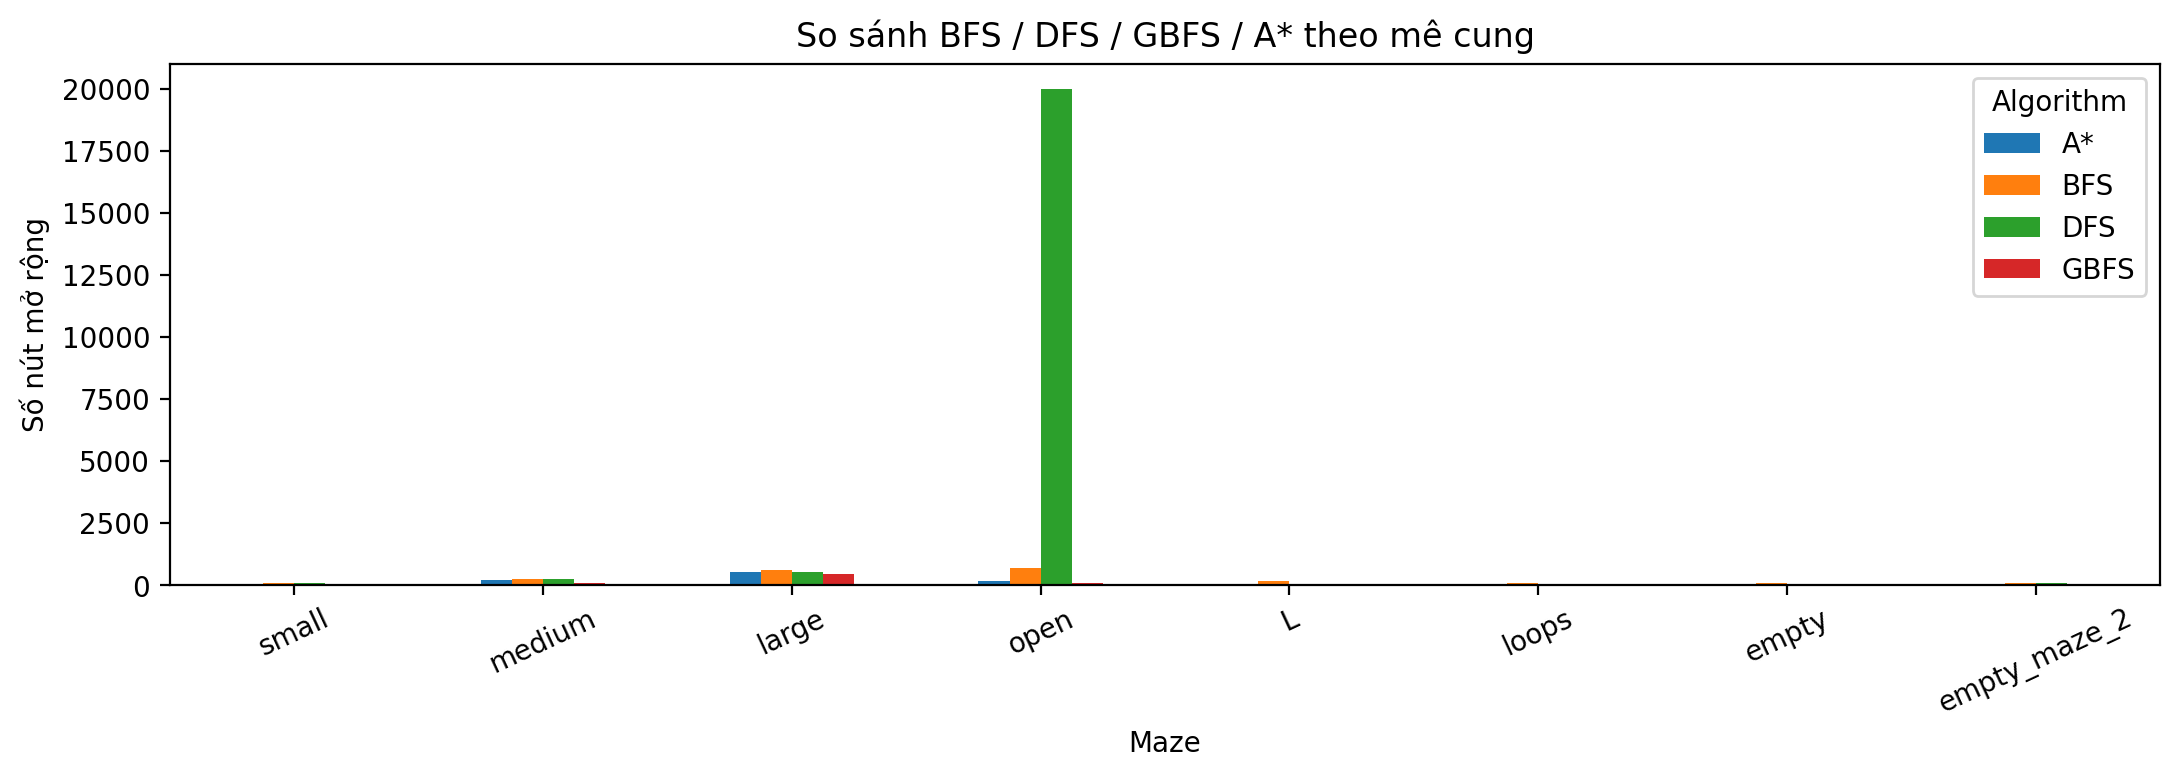

BFS | FOUND | path cost = 19


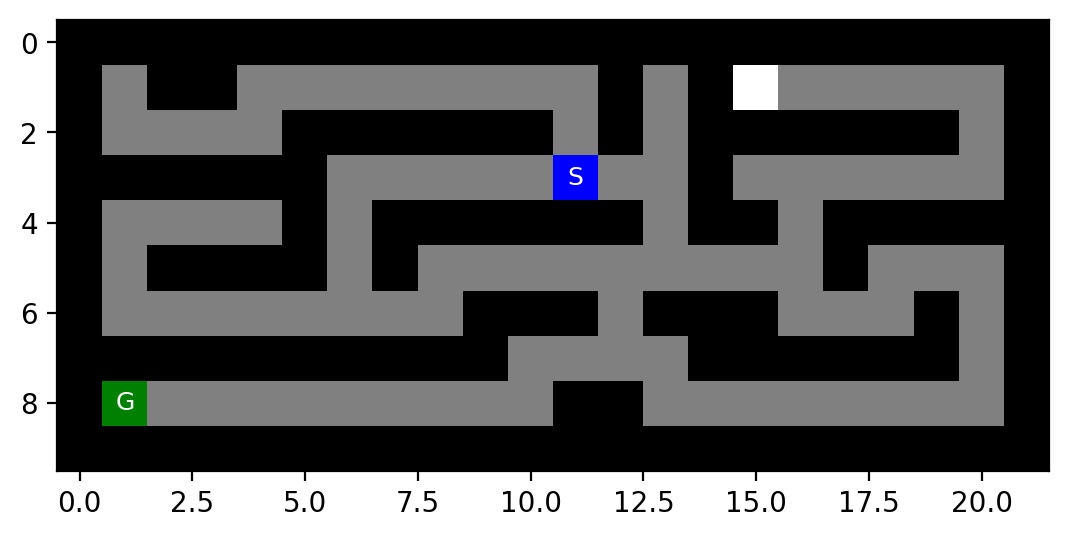

DFS | FOUND | path cost = 37


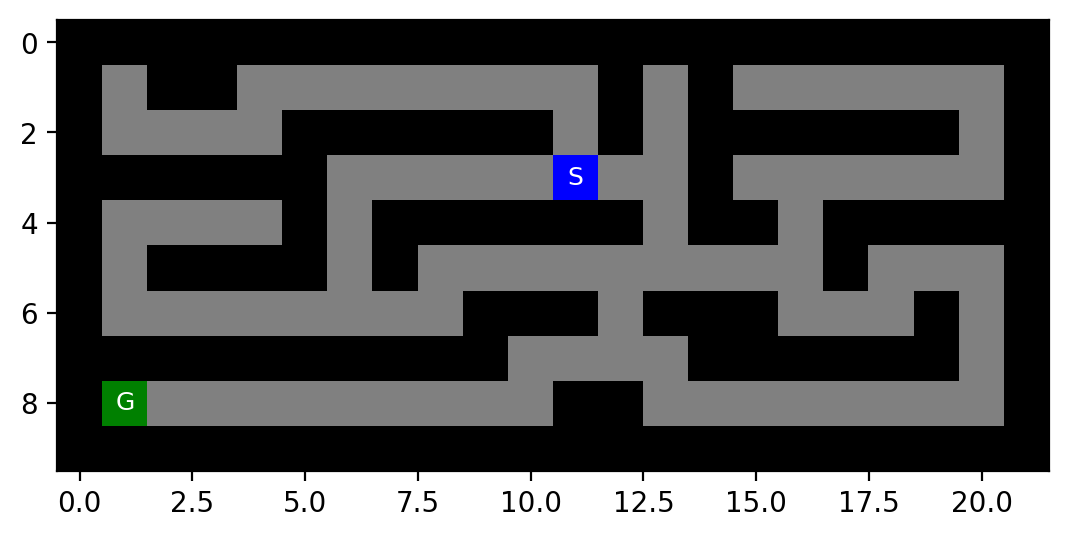

GBFS | FOUND | path cost = 29


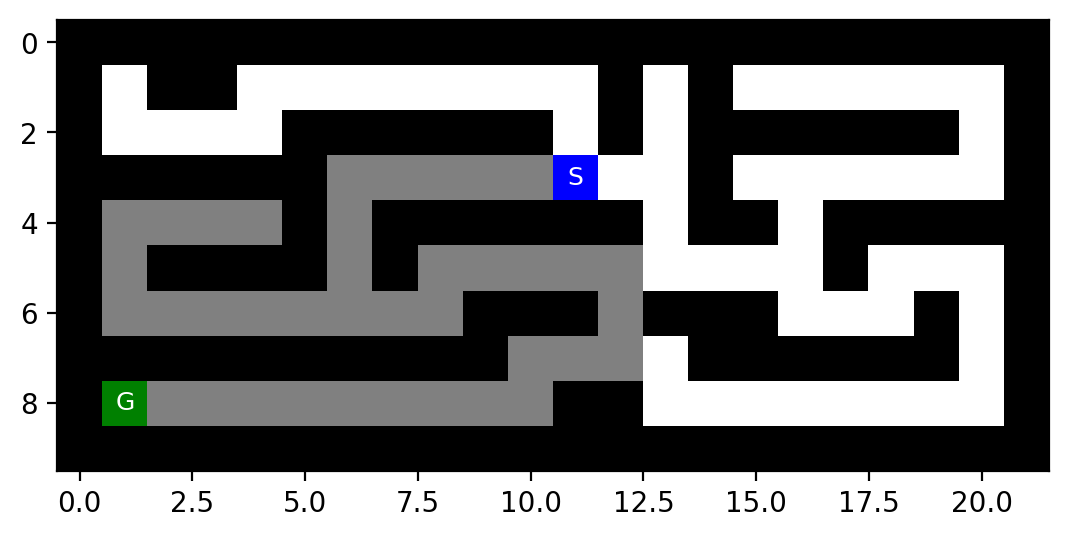

A* | FOUND | path cost = 19


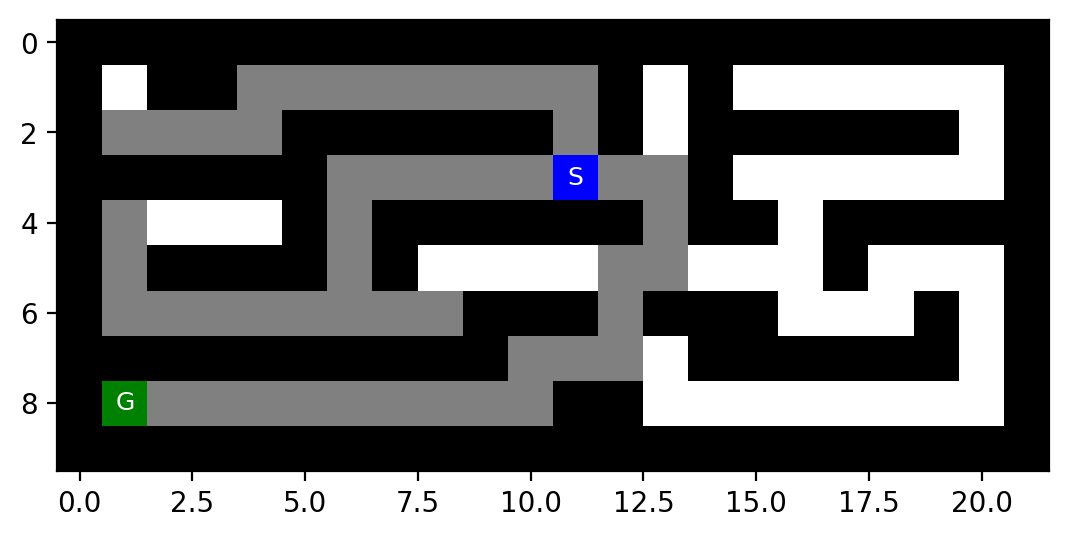

In [16]:
# Vẽ kết quả thực nghiệm và đường đi minh họa, không sửa bản đồ đầu vào
fig, ax=plt.subplots(figsize=(11,4))
plotdata=results_bai8.pivot(index='Maze',columns='Algorithm',values='Nodes expanded')
plotdata.reindex(MAZE_FILES_BAI8.keys()).plot(kind='bar',ax=ax)
ax.set_ylabel('Số nút mở rộng'); ax.set_title('So sánh BFS / DFS / GBFS / A* theo mê cung')
ax.tick_params(axis='x',rotation=25)
fig.tight_layout(); plt.savefig('hinh_bai8_so_nut_mo_rong.png',dpi=160);plt.show()

# Dùng bản đồ riêng cho từng lần tìm kiếm; trace CHỈ thu thập để hiển thị.
for alg in ['BFS','DFS','GBFS','A*']:
    example=mazes_bai8['small']
    s,g=mh.find_pos(example,'S'),mh.find_pos(example,'G')
    if alg=='BFS': example_result=bfs_search(example,s,g,trace=True)
    elif alg=='DFS': example_result=dfs_search(example,s,g,trace=True,max_expansions=20000)
    else: example_result=best_first_search(example,s,g,strategy=alg,trace=True)
    print(alg,'|',example_result['status'],'| path cost =',example_result['path_cost'])
    show_solution(example,example_result)

Discuss the most important lessons you have learned from implementing the different search strategies. 

### Lời giải Task 4 — Nhận xét kết quả

1. **BFS** duyệt theo từng tầng; với chi phí bước bằng nhau và `reached`, luôn trả về đường ngắn nhất. Đổi lại số trạng thái lưu trong bộ nhớ tăng theo quy mô vùng đã khám phá.
2. **DFS** duyệt sâu theo nhánh, chỉ giữ stack hiện hành và kiểm tra chu trình trên nhánh. Do đó thời gian có thể tăng mạnh do phải duyệt lại trạng thái từ những nhánh khác nhau; nghiệm tìm được không bảo đảm tối ưu. Với mê cung phức tạp, giới hạn thử nghiệm có thể gây `LIMIT_REACHED`.
3. **GBFS** quan sát $h(n)$ để hướng về đích, thường nhanh nhưng có thể chọn đường vòng trong vùng có tường.
4. **A\*** kết hợp $g(n)$ và $h(n)$, bảo đảm kết quả tối ưu với Manhattan nhất quán và thủ tục cập nhật trạng thái đúng; số nút mở rộng có thể ít hơn BFS nhưng không bắt buộc trong mọi bản đồ/cách phá hòa.
5. **Bộ nhớ:** so sánh `max_frontier` và `max_memory (proxy)` phải lưu ý cài đặt DFS theo stack frame chỉ giữ nhánh hoạt động, còn GBFS/A* cần heap và bảng trạng thái. `expanded_trace` khi bật để vẽ không tính vào phần bộ nhớ thuật toán.

**Kết luận:** Khả năng tìm lời giải, chất lượng lời giải và tài nguyên là ba tiêu chí khác nhau. Không có thuật toán nào luôn tốt nhất trong mọi mê cung; lựa chọn tùy mục tiêu tối ưu, cấu trúc bản đồ và nguồn lực tính toán.

## Advanced task: IDS and Multiple goals

* __Graduate students__ need to complete this task [10 points]
* __Undergraduate students__ can attempt this as a bonus task [max +5 bonus points].

### IDS 
Implement IDS (iterative deepening search) using your DFS implementation. Test IDS on the mazes above. You may run into some issues with mazes with open spaces. If you cannot resolve the issues, then report and discuss what causes the problems.

In [17]:
# Advanced Task: IDS — thử tất cả mê cung với ngân sách thực nghiệm hữu hạn
ids_rows=[]
for name,grid in mazes_bai8.items():
    s,g=mh.find_pos(grid,'S'),mh.find_pos(grid,'G')
    r=ids_search(grid,s,g,max_expansions_per_iteration=3000,max_total_expansions=12000)
    if r['status']=='FOUND':
        assert verify_plan(grid,s,g,r['actions'])
        assert r['path_cost']==int(results_bai8.query('Maze == @name and Algorithm == "BFS"')['Path cost'].iloc[0])
    ids_rows.append(dict(Maze=name,Status=r['status'],Path_cost=r['path_cost'],
                         Iterations=r['iterations'],Limit_increases=r['increases'],
                         Total_expanded=r['n_expanded'],Max_frontier=r['max_frontier']))
ids_table_bai8=pd.DataFrame(ids_rows)
display(ids_table_bai8)
print('Ví dụ lịch sử giới hạn của IDS trên small:')
display(pd.DataFrame(ids_search(mazes_bai8['small'],
         mh.find_pos(mazes_bai8['small'],'S'),mh.find_pos(mazes_bai8['small'],'G'),
         max_total_expansions=15000)['history']).tail(8))
ids_table_bai8.to_csv('ket_qua_bai8_IDS.csv',index=False,encoding='utf-8-sig')

,Maze,Status,Path_cost,Iterations,Limit_increases,Total_expanded,Max_frontier
0,small,FOUND,19.0,20,19,1051,20
1,medium,LIMIT_REACHED,NaN,63,62,12000,63
2,large,LIMIT_REACHED,NaN,95,94,12000,94
3,open,LIMIT_REACHED,NaN,10,9,5555,10
4,L,LIMIT_REACHED,NaN,8,7,4828,8
5,loops,LIMIT_REACHED,NaN,17,16,8326,17
6,empty,LIMIT_REACHED,NaN,9,8,5060,9
7,empty_maze_2,LIMIT_REACHED,NaN,9,8,5060,9


Ví dụ lịch sử giới hạn của IDS trên small:


,limit,status,expanded
12,12,CUTOFF,69
13,13,CUTOFF,78
14,14,CUTOFF,87
15,15,CUTOFF,95
16,16,CUTOFF,104
17,17,CUTOFF,114
18,18,CUTOFF,125
19,19,FOUND,75


**Giải thích IDS:** IDS thực thi DLS tuần tự với giới hạn $0,1,2,\ldots$; mỗi lượt chỉ giữ ngăn xếp DFS hiện hành, không giữ toàn bộ các lớp tìm kiếm như BFS. Lời giải đầu tiên ở giới hạn $d$ có độ sâu tối ưu khi chi phí bước bằng nhau và cycle checking phù hợp. Cái giá phải trả là mở rộng lại những nút nông ở các lượt trước. `LIMIT_REACHED` trong bảng ở trên phản ánh **ngân sách an toàn để chạy notebook**, không khẳng định mê cung vô nghiệm. IDS không dùng `reached` toàn cục giữa các lượt.

### Multiple Goals 
Create a few mazes with multiple goals by adding one or two more goals to the medium size maze. The agent is done when it finds one of the goals.
Solve the maze with your implementations for DFS, BFS, and IDS. Run experiments to show which implementations find the optimal solution and which do not. Discuss why that is the case.

Các goal (kèm gốc): [(np.int64(1), np.int64(9)), (np.int64(1), np.int64(30)), (np.int64(16), np.int64(1))] | độ sâu tối ưu: 4


,Algorithm,Status,Path cost,Expanded,Max frontier
0,BFS,FOUND,4,8,2
1,DFS,FOUND,84,84,84
2,IDS,FOUND,4,24,5


Bản đồ nhiều đích (trong bản sao medium):


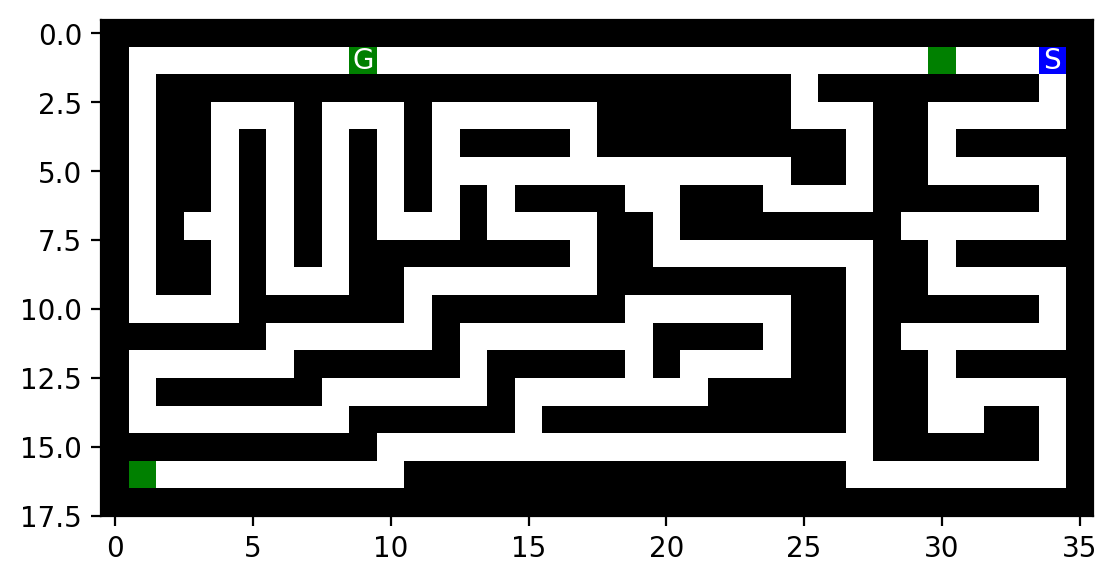

BFS tìm nghiệm tối ưu vì dừng tại tầng có một trong các goal; DFS không bảo đảm tối ưu.


In [18]:
# Advanced Task: MULTIPLE GOALS — tạo bản đồ mới từ medium, không sửa bản đồ gốc
medium_original=mazes_bai8['medium']
medium_multi=medium_original.copy()
source=mh.find_pos(medium_multi,'S')
# Tự chọn hai vị trí hợp lệ ở các khoảng cách khác nhau từ S.
q=deque([source]); distance={source:0}
while q:
    pos=q.popleft()
    for _,nxt in valid_neighbors(medium_multi,pos):
        if nxt not in distance:
            distance[nxt]=distance[pos]+1; q.append(nxt)
old_goal=mh.find_pos(medium_multi,'G')
candidates=[p for p,d in distance.items() if medium_multi[p]==' ']
# chọn các ô có khoảng cách gần giá trị mục tiêu, có khoảng cách đến S đủ khác nhau
near=min(candidates,key=lambda p:(abs(distance[p]-4),p))
far=min((p for p in candidates if p!=near),key=lambda p:(abs(distance[p]-25),p))
medium_multi[near]='G'; medium_multi[far]='G'
goal_list=[tuple(p) for p in np.argwhere(medium_multi=='G')]
print('Các goal (kèm gốc):',goal_list,'| độ sâu tối ưu:',min(distance[p] for p in goal_list))

multi_results=[]
for alg in ['BFS','DFS','IDS']:
    if alg=='BFS': r=bfs_search(medium_multi,source,goal_list)
    elif alg=='DFS': r=dfs_search(medium_multi,source,goal_list,max_expansions=30000)
    else: r=ids_search(medium_multi,source,goal_list,max_total_expansions=18000,max_expansions_per_iteration=5000)
    if r['status']=='FOUND': assert verify_plan(medium_multi,source,goal_list,r['actions'])
    multi_results.append({'Algorithm':alg,'Status':r['status'],'Path cost':r['path_cost'],
                          'Expanded':r['n_expanded'],'Max frontier':r['max_frontier']})
display(pd.DataFrame(multi_results))
print('Bản đồ nhiều đích (trong bản sao medium):')
mh.show_maze(medium_multi)
print('BFS tìm nghiệm tối ưu vì dừng tại tầng có một trong các goal; DFS không bảo đảm tối ưu.')

**Phân tích nhiều đích:** Đích trở thành **một tập** $G=\{g_1,g_2,\ldots\}$; thành công ngay khi nút được lấy ra có vị trí thuộc $G$. Với BFS/IDS và chi phí bước 1, độ sâu lời giải tối ưu là $d=\min_{g\in G}d(S,g)$. DFS có thể phát hiện một đích xa hơn trước vì đi theo nhánh sâu; so sánh số liệu từ bảng trên trước khi kết luận trường hợp cụ thể. Dữ liệu nguồn `medium_maze.txt` không bị thay đổi; các ký hiệu `G` bổ sung chỉ được đặt trên bản sao.

## More Advanced Problems to Think About (not for credit)

If the assignment was to easy for yuo then you can think about the following problems. These problems are challenging and not part of this assignment. 

### Intersection as States
Instead of defining each square as a state, use only intersections as states. Now the storage requirement is reduced, but the path length between two intersections can be different. If we use total path length measured as the number of squares as path cost, how can we make sure that BFS and iterative deepening search is optimal? Change the code to do so.

### Intersection as States (câu hỏi mở rộng, không tính điểm)

Chỉ giữ nút tại ngã rẽ và ngã ba sẽ tạo các cạnh có trọng số bằng số bước đi dọc hành lang. **BFS và IDS theo số cạnh không còn bảo đảm tối ưu theo tổng số bước**, vì các cạnh đã có độ dài khác nhau. Muốn tối ưu chi phí thực, nên dùng Uniform-Cost Search (Dijkstra) hoặc A* với chi phí cạnh đúng; một lựa chọn khác là tách cạnh dài thành các bước đơn vị.

### Weighted A* search
Modify your A* search to add weights (see text book) and explore how different weights influence the result.

In [19]:
# Weighted A*: phần mở rộng (không tính điểm), giữ chung máy đo với A*
weighted_rows=[]
for w in [1.0,1.5,2.0,3.0,5.0]:
    r=best_first_search(mazes_bai8['small'],
         mh.find_pos(mazes_bai8['small'],'S'),mh.find_pos(mazes_bai8['small'],'G'),
         strategy='A*',weight=w)
    weighted_rows.append({'w':w,'Path cost':r['path_cost'],'Expanded':r['n_expanded']})
display(pd.DataFrame(weighted_rows))
print('w=1 là A*; w>1 có thể đánh đổi tính tối ưu để tập trung mạnh hơn theo h(n).')

,w,Path cost,Expanded
0,1.0,19,49
1,1.5,19,53
2,2.0,19,55
3,3.0,19,57
4,5.0,29,41


w=1 là A*; w>1 có thể đánh đổi tính tối ưu để tập trung mạnh hơn theo h(n).


### Unknown Maze
What happens if the agent does not know the layout of the maze in advance? This means that the agent faces an unknown environment, where it does not know the transition function. How does the environment look then (PEAS description)? How would you implement a rational agent to solve the maze? What if the agent still has a GPS device to tell the distance to the goal?

### Unknown Maze — PEAS và tác tử hợp lý (câu hỏi mở rộng, không tính điểm)

Nếu không biết bản đồ, tác tử **không thể lập kế hoạch open-loop hoàn chỉnh** dựa vào chuyển trạng thái đã biết. Mô tả PEAS:

| Thành phần | Nội dung |
|:--|:--|
| Performance measure | Đến được đích; tối thiểu số bước, va chạm, thời gian và chi phí thăm dò |
| Environment | Mê cung chưa biết, tường, giao lộ, điểm bắt đầu và đích |
| Actuators | Lệnh di chuyển N/E/S/W |
| Sensors | Vị trí hiện tại và cảm biến quan sát tường/ô lân cận; có thể có GPS hoặc tín hiệu khoảng cách đến đích |

Giải pháp hợp lý: theo chu trình **quan sát → cập nhật bản đồ tin cậy → lập kế hoạch lại → thực hiện một phần kế hoạch → quan sát tiếp**, kết hợp khám phá với tìm đường. Khoảng cách do GPS cung cấp có thể dùng làm heuristic định hướng nếu là cận dưới của chi phí thật; nếu dữ liệu GPS chỉ là ước lượng sai lệch có thể lớn hơn chi phí thực thì không nên khẳng định A* vẫn bảo đảm tối ưu.